# NLP Project Phase 2: Word Representations
**Dataset:** IMDB 50K movie reviews, binary sentiment. **Corpus:** the cleaned dataset from Phase 1 (`output/cleaned_data.csv`, 49,582 reviews), used unchanged for *every* representation so comparisons are fair.

| Part | Content |
|---|---|
| A | Count-based: Bag of Words, TF-IDF, N-grams, hand-worked numerical example |
| B | Learned embeddings: Word2Vec CBOW, Word2Vec Skip-gram, fastText |
| C | Probing (neighbours, similarities, analogies) and count-based vs learned comparison |
| D | Saved models and the `vectorize()` interface for Phase 3 |

The embedding models are trained **once** by `python src/representations.py` and only *loaded* here (Part D requirement: no retraining in the loading path). Run that script first.

In [1]:
import sys, re, time, json, math, gc
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.sparse.linalg import norm as spnorm
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

sys.path.insert(0, "../src")
import representations as R
import vectorize as V

FIG = Path("../output/figures"); FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 120, "display.width", 200)

df = R.load_corpus()
texts = df["clean_text"].tolist()
summary = json.load(open("../output/phase2_summary.json"))
RESULTS = {}   # key numbers, saved at the end to output/phase2_results.json
print(f"Corpus: {len(texts):,} cleaned reviews, {df.n_tokens.sum():,} tokens")
df.head(3)

Corpus: 49,582 cleaned reviews, 6,007,695 tokens


,orig_id,sentiment,label,clean_text,n_tokens
0,0,positive,1,one reviewer mention watch oz episode hook right exactly happen first thing strike oz brutality unflinching scene vi...,171
1,1,positive,1,wonderful little production film technique unassuming old time bbc fashion give comfort sometimes discomforting sens...,88
2,2,positive,1,think wonderful way spend time hot summer weekend sit air condition theater watch light hearted comedy plot simplist...,87


# Part A: Count-based representations

## A1. Bag of Words
`CountVectorizer` builds a **document-term matrix**: one row per review, one column per vocabulary word, each cell is how many times the word occurs in the review. Word order is thrown away. Our cleaned text is already lower-case, space-separated tokens, so we split on whitespace only (`token_pattern=r"\S+"`) and do not lower-case again.

In [2]:
bow = R.make_bow()
X_bow = bow.fit_transform(texts)
n_docs, n_feat = X_bow.shape
cells_total = n_docs * n_feat
zeros = cells_total - X_bow.nnz
sparsity = 100 * (1 - X_bow.nnz / cells_total)
sparse_mb = (X_bow.data.nbytes + X_bow.indices.nbytes + X_bow.indptr.nbytes) / 1e6
dense_gb = cells_total * 4 / 1e9
distinct_per_doc = np.diff(X_bow.indptr)

print(f"Shape (documents x vocabulary): {X_bow.shape}")
print(f"Total cells              : {cells_total:,}")
print(f"Non-zero entries         : {X_bow.nnz:,}")
print(f"Zero entries             : {zeros:,}")
print(f"Sparsity (% zero cells)  : {sparsity:.4f} %")
print(f"Distinct words / review  : mean {distinct_per_doc.mean():.1f}, median {np.median(distinct_per_doc):.0f}")
print(f"Memory as sparse (CSR)   : {sparse_mb:.1f} MB   vs   as a dense int32 array: {dense_gb:.1f} GB")

assert bow.vocabulary_ == R.load_count_vectorizer("bow").vocabulary_, "saved BoW vectorizer differs"
print("OK: identical to the saved models/bow_vectorizer.joblib")

vocab = bow.get_feature_names_out()
counts = np.asarray(X_bow.sum(axis=0)).ravel()
dfc = X_bow.getnnz(axis=0)               # document frequency of every word
top = (pd.DataFrame({"word": vocab, "total_count": counts, "doc_freq": dfc})
         .sort_values("total_count", ascending=False).head(10).reset_index(drop=True))
display(top)

RESULTS["bow"] = dict(shape=[int(n_docs), int(n_feat)], nonzero=int(X_bow.nnz), zeros=int(zeros),
                      sparsity_pct=round(sparsity, 4), sparse_mb=round(sparse_mb, 1), dense_gb=round(dense_gb, 1),
                      distinct_per_doc_mean=round(float(distinct_per_doc.mean()), 1))

Shape (documents x vocabulary): (49582, 79320)
Total cells              : 3,932,844,240
Non-zero entries         : 4,660,849
Zero entries             : 3,928,183,391
Sparsity (% zero cells)  : 99.8815 %
Distinct words / review  : mean 94.0, median 74
Memory as sparse (CSR)   : 37.5 MB   vs   as a dense int32 array: 15.7 GB
OK: identical to the saved models/bow_vectorizer.joblib


,word,total_count,doc_freq
0,not,126357,40457
1,movie,102500,32158
2,film,95225,29556
3,one,55038,28661
4,make,45835,25731
5,like,43939,24441
6,see,41277,24406
7,get,35182,20940
8,time,31654,20352
9,would,30981,18931


## A2. TF-IDF
Raw counts reward words that are merely *frequent*. TF-IDF multiplies the term frequency by an **inverse document frequency**, so a word is important if it is frequent in *this* review but rare across the corpus.

scikit-learn's formula (smooth idf, then L2 normalisation of each row):

`idf(t) = ln((1 + N) / (1 + df(t))) + 1`  and  `tfidf(t, d) = tf(t, d) × idf(t)`

where N is the number of documents and df(t) the number of documents containing t.

In [3]:
tfidf = R.make_tfidf()
X_tfidf = tfidf.fit_transform(texts)
assert X_tfidf.shape == X_bow.shape and (tfidf.get_feature_names_out() == vocab).all()
N = n_docs
idf = tfidf.idf_
glob = pd.DataFrame({"word": vocab, "doc_freq": dfc, "idf (sklearn, smoothed)": idf,
                     "ln(N/df) (textbook)": np.log(N / dfc)})
print(f"TF-IDF matrix shape: {X_tfidf.shape}, sparsity {100 * (1 - X_tfidf.nnz / (N * n_feat)):.4f} %")
print(f"idf range: {idf.min():.3f} (most common word) ... {idf.max():.3f} (words in one review only)\n")
print("Most common words -> smallest idf:")
display(glob.sort_values("doc_freq", ascending=False).head(8).reset_index(drop=True).round(3))
print("Words that occur in a single review -> largest idf (examples):")
display(glob[glob.doc_freq == 1].head(5).reset_index(drop=True).round(3))

TF-IDF matrix shape: (49582, 79320), sparsity 99.8815 %
idf range: 1.203 (most common word) ... 11.118 (words in one review only)

Most common words -> smallest idf:


,word,doc_freq,"idf (sklearn, smoothed)",ln(N/df) (textbook)
0,not,40457,1.203,0.203
1,movie,32158,1.433,0.433
2,film,29556,1.517,0.517
3,one,28661,1.548,0.548
4,make,25731,1.656,0.656
5,like,24441,1.707,0.707
6,see,24406,1.709,0.709
7,get,20940,1.862,0.862


Words that occur in a single review -> largest idf (examples):


,word,doc_freq,"idf (sklearn, smoothed)",ln(N/df) (textbook)
0,aab,1,11.118,10.811
1,aada,1,11.118,10.811
2,aadha,1,11.118,10.811
3,aagghh,1,11.118,10.811
4,aaghh,1,11.118,10.811


Review (orig_id 5, positive, 56 tokens):
probably time favorite movie story selflessness sacrifice dedication noble cause not preachy bore never get old despite see time last year paul lukas performance bring tear eye bette davis one truly sympathetic role delight kid grandma say like dress midget child make fun watch mother slow awaken happen world roof believable startle dozen thumb would movie 

HIGH weight words in this review:


,word,count in review,doc_freq,idf,tf-idf weight
0,selflessness,1,4,10.202,0.293
1,lukas,1,42,8.050,0.231
2,midget,1,70,7.549,0.217
3,dedication,1,78,7.442,0.214
4,grandma,1,81,7.405,0.213
5,bette,1,134,6.906,0.198
6,preachy,1,135,6.899,0.198
7,roof,1,155,6.762,0.194


LOW weight words in this review (common words):


,word,count in review,doc_freq,idf,tf-idf weight
0,not,1,40457,1.203,0.035
1,one,1,28661,1.548,0.044
2,make,1,25731,1.656,0.048
3,like,1,24441,1.707,0.049
4,see,1,24406,1.709,0.049
5,get,1,20940,1.862,0.053
6,would,1,18931,1.963,0.056
7,watch,1,18141,2.005,0.058


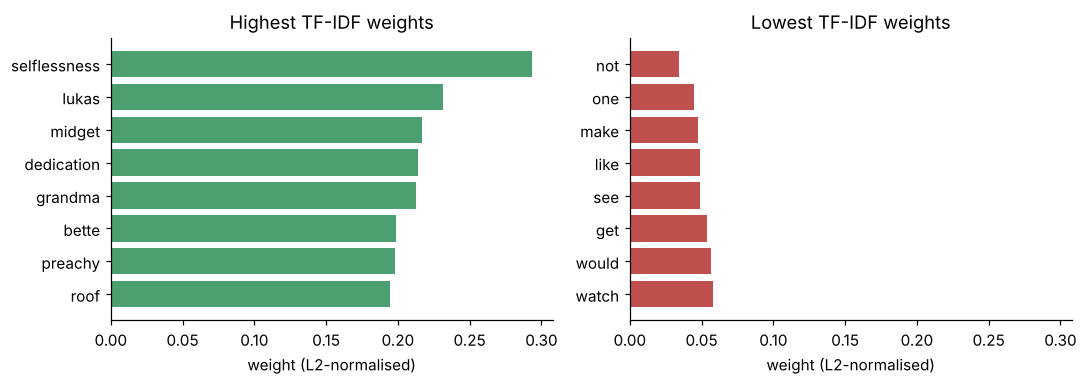

In [4]:
# A concrete review: the first one of 40-80 tokens that contains both "movie" and "not"
cand = df[df.n_tokens.between(40, 80)
          & df.clean_text.str.contains(r"\bmovie\b") & df.clean_text.str.contains(r"\bnot\b")]
i = cand.index[0]
print(f"Review (orig_id {df.loc[i, 'orig_id']}, {df.loc[i, 'sentiment']}, {df.loc[i, 'n_tokens']} tokens):")
print(df.loc[i, "clean_text"], "\n")

row, brow = X_tfidf[i], X_bow[i]
ex = pd.DataFrame({"word": vocab[row.indices],
                   "count in review": brow[:, row.indices].toarray().ravel(),
                   "doc_freq": dfc[row.indices],
                   "idf": idf[row.indices],
                   "tf-idf weight": row.data})
high = ex.sort_values("tf-idf weight", ascending=False).head(8).reset_index(drop=True)
low = ex.sort_values("tf-idf weight").head(8).reset_index(drop=True)
print("HIGH weight words in this review:"); display(high.round(3))
print("LOW weight words in this review (common words):"); display(low.round(3))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharex=True)
ax[0].barh(high.word[::-1], high["tf-idf weight"][::-1], color="#4c9f70"); ax[0].set_title("Highest TF-IDF weights")
ax[1].barh(low.word[::-1], low["tf-idf weight"][::-1], color="#c0504d"); ax[1].set_title("Lowest TF-IDF weights")
for a in ax: a.set_xlabel("weight (L2-normalised)")
plt.tight_layout(); plt.savefig(FIG / "phase2_tfidf_example.png"); plt.show()

RESULTS["tfidf"] = dict(shape=[int(N), int(n_feat)], idf_min=round(float(idf.min()), 3), idf_max=round(float(idf.max()), 3),
                        example_orig_id=int(df.loc[i, "orig_id"]),
                        high=high[["word", "count in review", "doc_freq", "idf", "tf-idf weight"]].round(3).to_dict("records")[:5],
                        low=low[["word", "count in review", "doc_freq", "idf", "tf-idf weight"]].round(3).to_dict("records")[:5],
                        common=glob.sort_values("doc_freq", ascending=False).head(5).round(3).to_dict("records"))

### TF-IDF: what gets a high weight, what gets pushed down
For the example review (orig_id 5, a positive review of 56 tokens) every word occurs exactly once (tf = 1), so the differences in weight come **only from idf**:

| | word | document frequency | idf | TF-IDF weight |
|---|---|---|---|---|
| HIGH | selflessness | 4 reviews | 10.20 | 0.293 |
| HIGH | lukas | 42 | 8.05 | 0.231 |
| HIGH | midget | 70 | 7.55 | 0.217 |
| LOW | not | 40,457 | 1.20 | 0.035 |
| LOW | one | 28,661 | 1.55 | 0.044 |
| LOW | make | 25,731 | 1.66 | 0.048 |

**Why.** idf is large when a word appears in few reviews. *selflessness* appears in 4 of 49,582 reviews, so seeing it tells us a lot about *this* review; *not*, *one* and *make* appear in more than half of all reviews, so they say almost nothing that separates this review from the others. The highest-weighted word is about 8 times heavier than *not*.

**Two honest remarks.**
1. With scikit-learn's *smoothed* idf no weight reaches exactly zero (idf is always at least 1; its smallest value in our corpus is 1.203 for *not*). The textbook formula ln(N/df) does drive the common words towards zero (0.20 for *not*, 0.43 for *movie*), as the table in A2 shows. In both versions common words end up with the smallest weights.
2. TF-IDF measures how *distinctive* a word is, not how *useful for sentiment* it is. The top-weighted words here (a name, *midget*, *selflessness*) are rare but not sentiment words, and *not*, which flips sentiment, gets the lowest weight. A classifier can still use these weights, but this is a limit of TF-IDF.

## A3. N-grams
We rebuild the Bag of Words with n-gram ranges (1,1), (1,2) and (1,3) (all unigrams, plus all bigrams, plus all trigrams) and watch how the number of features and the sparsity change. "df >= 5" shows what is left if n-grams seen in fewer than 5 reviews are pruned.

(1,1) done in 2s


(1,2) done in 14s


(1,3) done in 35s


,n-gram range,features,non-zeros,sparsity %,features seen once %,features with df>=5,sparsity % (df>=5),sparse MB,fit seconds
0,"(1,1)",79320,4660849,99.881,40.639,27136,99.660,37.485,1.934
1,"(1,2)",2681743,10492778,99.992,75.493,182415,99.919,84.141,13.890
2,"(1,3)",7973854,16383655,99.996,88.397,213757,99.928,131.268,34.976


Features of the (1,3) matrix by order: {1: 79320, 2: 2602423, 3: 5292111}
Most frequent bigrams : [('movie not', 4926), ('not even', 4418), ('could not', 3991), ('film not', 3714), ('look like', 3685), ('not know', 3563), ('watch movie', 3089), ('would not', 2995)]
Most frequent trigrams: [('movie ever see', 913), ('worst movie ever', 747), ('not waste time', 548), ('film ever see', 455), ('movie ever make', 384), ('make no sense', 360), ('worst film ever', 349), ('film ever make', 324)]


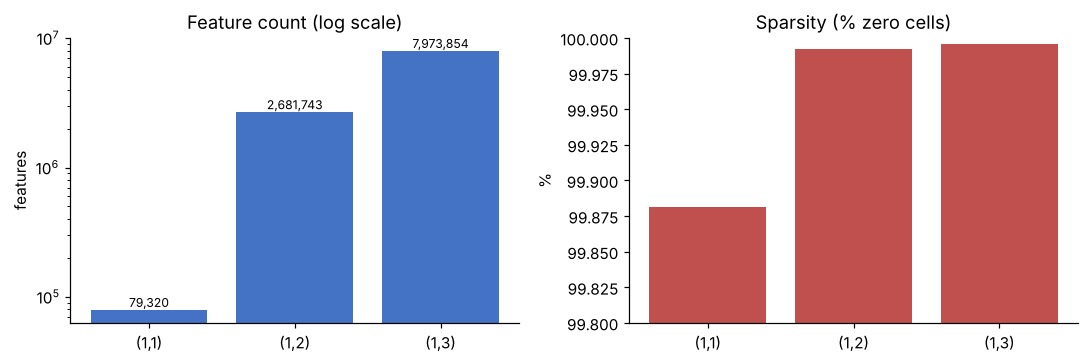

In [5]:
rows, top_ng = [], {}
for n in (1, 2, 3):
    cv = CountVectorizer(ngram_range=(1, n), token_pattern=R.TOKEN_PATTERN, lowercase=False, dtype=np.int32)
    t0 = time.time(); X = cv.fit_transform(texts); secs = time.time() - t0
    dfn = X.getnnz(axis=0)
    keep = dfn >= 5
    sums = np.asarray(X.sum(axis=0)).ravel()
    rows.append({
        "n-gram range": f"(1,{n})",
        "features": X.shape[1],
        "non-zeros": X.nnz,
        "sparsity %": 100 * (1 - X.nnz / (X.shape[0] * X.shape[1])),
        "features seen once %": 100 * (sums == 1).mean(),
        "features with df>=5": int(keep.sum()),
        "sparsity % (df>=5)": 100 * (1 - dfn[keep].sum() / (X.shape[0] * keep.sum())),
        "sparse MB": (X.data.nbytes + X.indices.nbytes + X.indptr.nbytes) / 1e6,
        "fit seconds": secs,
    })
    if n == 3:   # most frequent bigrams / trigrams, taken from the biggest matrix
        order = np.empty(X.shape[1], dtype=np.int8)
        for term, idx in cv.vocabulary_.items():
            order[idx] = term.count(" ") + 1
        per_order = {int(k): int((order == k).sum()) for k in (1, 2, 3)}
        for k in (2, 3):
            masked = np.where(order == k, sums, -1)
            best = np.argpartition(masked, -8)[-8:]
            best = best[np.argsort(-masked[best])]
            wanted = set(best.tolist())
            inv = {idx: term for term, idx in cv.vocabulary_.items() if idx in wanted}
            top_ng[k] = [(inv[b], int(sums[b])) for b in best]
    print(f"(1,{n}) done in {secs:.0f}s")
    del X, cv, sums, dfn; gc.collect()

ng = pd.DataFrame(rows)
display(ng.round(3))
print("Features of the (1,3) matrix by order:", per_order)
print("Most frequent bigrams :", top_ng[2])
print("Most frequent trigrams:", top_ng[3])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].bar(ng["n-gram range"], ng["features"], color="#4472c4"); ax[0].set_yscale("log")
ax[0].set_title("Feature count (log scale)"); ax[0].set_ylabel("features")
for x, v in zip(ng["n-gram range"], ng["features"]): ax[0].text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
ax[1].bar(ng["n-gram range"], ng["sparsity %"], color="#c0504d"); ax[1].set_ylim(99.8, 100)
ax[1].set_title("Sparsity (% zero cells)"); ax[1].set_ylabel("%")
plt.tight_layout(); plt.savefig(FIG / "phase2_ngram_growth.png"); plt.show()

RESULTS["ngram"] = ng.round(4).to_dict("records")
RESULTS["ngram_order_counts"] = per_order
RESULTS["top_bigrams"] = top_ng[2][:5]; RESULTS["top_trigrams"] = top_ng[3][:5]

In [6]:
# TF-IDF with unigrams + bigrams (the configuration we save for Phase 3: min_df=5)
tfidf_ng = R.make_tfidf_ngram()
X_ng = tfidf_ng.fit_transform(texts)
print("TF-IDF (1,2), min_df=5 shape:", X_ng.shape,
      f"| sparsity {100 * (1 - X_ng.nnz / (X_ng.shape[0] * X_ng.shape[1])):.4f} %")
assert list(X_ng.shape) == summary["tfidf_ngram"]["shape"]

names = tfidf_ng.get_feature_names_out()
r = X_ng[i]
w = pd.DataFrame({"feature": names[r.indices], "tf-idf": r.data})
w["type"] = np.where(w.feature.str.contains(" "), "bigram", "unigram")
print("Top-weighted features of the example review (orig_id %d):" % df.loc[i, "orig_id"])
display(w.sort_values("tf-idf", ascending=False).head(8).reset_index(drop=True).round(3))
RESULTS["tfidf_ngram"] = dict(shape=list(X_ng.shape),
                              sparsity_pct=round(100 * (1 - X_ng.nnz / (X_ng.shape[0] * X_ng.shape[1])), 4))
del X_ng; gc.collect()

TF-IDF (1,2), min_df=5 shape: (49582, 182415) | sparsity 99.9192 %
Top-weighted features of the example review (orig_id 5):


,feature,tf-idf,type
0,despite see,0.180,bigram
1,davis one,0.177,bigram
2,watch mother,0.171,bigram
3,noble cause,0.169,bigram
4,thumb would,0.169,bigram
5,not preachy,0.168,bigram
6,sympathetic role,0.166,bigram
7,bore never,0.166,bigram


3027

### N-grams: vocabulary growth and the sparsity trade-off

| n-gram range | features | growth vs unigrams | non-zeros | sparsity | features seen only once | features with df >= 5 |
|---|---|---|---|---|---|---|
| (1,1) | 79,320 | 1x | 4,660,849 | 99.881 % | 40.6 % | 27,136 |
| (1,2) | 2,681,743 | 33.8x | 10,492,778 | 99.992 % | 75.5 % | 182,415 |
| (1,3) | 7,973,854 | 100.5x | 16,383,655 | 99.996 % | 88.4 % | 213,757 |

The (1,3) matrix contains 79,320 unigrams, 2,602,423 bigrams and 5,292,111 trigrams.

* **The vocabulary explodes** (about 34 times with bigrams, about 100 times with trigrams), while the number of non-zero cells only grows 2.3 and 3.5 times. A review of about 121 tokens can only contain about 121 bigrams and 121 trigrams, so the matrix gets wider much faster than it gets fuller, and **sparsity rises** from 99.881 % to 99.996 %.
* **Most n-grams are rare.** 75.5 % of all features in (1,2) and 88.4 % in (1,3) occur only once in the whole corpus. Such features cannot be learned from and mostly add noise and memory (sparse size 37 MB, 84 MB, 131 MB).
* **What n-grams add.** They recover short phrases and word order that unigrams lose, including negation phrases: the most frequent bigrams are *movie not* (4,926), *not even* (4,418), *could not* (3,991), and the most frequent trigrams are *movie ever see* (913), *worst movie ever* (747), *not waste time* (548), *make no sense* (360).
* **Pruning fixes most of the cost.** Keeping only n-grams that appear in at least 5 reviews leaves 182,415 features for (1,2) (about 15 times fewer than the raw 2.68 million) and 213,757 for (1,3). Going from bigrams to trigrams then adds only about 31,000 useful features, so we save the **(1,2), min_df=5** TF-IDF vectorizer for Phase 3.

## A4. Hand-worked numerical example
To check that we really understand the library, we take **4 very short real reviews** from the corpus and compute by hand (plain Python arithmetic, no library) one TF-IDF weight and one bigram, then confirm both against scikit-learn.

> **Handwritten copy:** the same arithmetic printed below must also be written by hand on paper, scanned (CamScanner) and attached to the report, as the assignment asks.

In [7]:
toy_ids = [19874, 27521, 27680, 28920]
toy = df.set_index("orig_id").loc[toy_ids, ["sentiment", "clean_text"]]
docs = toy.clean_text.tolist()
tok = [d.split() for d in docs]
N_toy = len(docs)
for k, (oid, row_) in enumerate(toy.iterrows(), 1):
    print(f"d{k} (orig_id {oid}, {row_.sentiment}): {row_.clean_text}")
print("\nN =", N_toy, "documents")

d1 (orig_id 19874, negative): movie terrible good effect
d2 (orig_id 27521, negative): read book forget movie
d3 (orig_id 27680, positive): great movie bad not available home video
d4 (orig_id 28920, negative): primary plot primary direction poor interpretation

N = 4 documents


In [8]:
# ---------- hand arithmetic: TF-IDF ----------
def df_of(term):  return sum(term in t for t in tok)
def tf_of(term, k): return tok[k].count(term)
def idf_of(term): return math.log((1 + N_toy) / (1 + df_of(term))) + 1

print("Formula: idf(t) = ln((1+N)/(1+df)) + 1,   tfidf = tf * idf,   then divide by the L2 norm of the row\n")

# (1) the word 'primary' in d4: it occurs TWICE and only in d4
t, k = "primary", 3
tf_, df_, idf_ = tf_of(t, k), df_of(t), idf_of(t)
print(f"--- word '{t}' in d4")
print(f"tf  = count of '{t}' in d4 = {tf_}")
print(f"df  = documents containing '{t}' = {df_}")
print(f"idf = ln((1+{N_toy})/(1+{df_})) + 1 = ln({(1 + N_toy) / (1 + df_):.4f}) + 1 = {math.log((1 + N_toy) / (1 + df_)):.4f} + 1 = {idf_:.4f}")
raw_primary = tf_ * idf_
print(f"tf-idf (before normalisation) = {tf_} x {idf_:.4f} = {raw_primary:.4f}")

# L2 normalisation of d4: every distinct word of d4
d4_terms = sorted(set(tok[3]))
d4_raw = {w_: tf_of(w_, 3) * idf_of(w_) for w_ in d4_terms}
norm = math.sqrt(sum(v ** 2 for v in d4_raw.values()))
terms_txt = " + ".join(f"{v:.4f}^2" for v in d4_raw.values())
print(f"L2 norm of d4 = sqrt({terms_txt}) = sqrt({sum(v ** 2 for v in d4_raw.values()):.4f}) = {norm:.4f}")
hand_norm_primary = raw_primary / norm
print(f"normalised tf-idf('primary', d4) = {raw_primary:.4f} / {norm:.4f} = {hand_norm_primary:.4f}")

# (2) a common word vs a rare word in d1: 'movie' (in 3 docs) vs 'terrible' (in 1 doc)
print("\n--- common vs rare word in d1")
for t in ("movie", "terrible"):
    print(f"'{t}': tf=1, df={df_of(t)}, idf = ln(5/{1 + df_of(t)}) + 1 = {idf_of(t):.4f}  ->  tf-idf = {idf_of(t):.4f}")

# ---------- compare with scikit-learn ----------
tv_raw = TfidfVectorizer(token_pattern=R.TOKEN_PATTERN, lowercase=False, norm=None)   # no L2 -> raw tf*idf
tv_l2 = TfidfVectorizer(token_pattern=R.TOKEN_PATTERN, lowercase=False)               # default, with L2
Xr, Xn = tv_raw.fit_transform(docs), tv_l2.fit_transform(docs)
col = tv_raw.vocabulary_["primary"]
lib_raw, lib_norm = Xr[3, col], Xn[3, col]
print(f"\nscikit-learn  raw tf-idf('primary', d4)        = {lib_raw:.4f}   (hand: {raw_primary:.4f})")
print(f"scikit-learn  normalised tf-idf('primary', d4) = {lib_norm:.4f}   (hand: {hand_norm_primary:.4f})")
assert np.isclose(lib_raw, raw_primary) and np.isclose(lib_norm, hand_norm_primary)
assert np.isclose(Xr[0, tv_raw.vocabulary_["movie"]], idf_of("movie"))
print("MATCH: the hand-worked TF-IDF weights equal the library output.")
RESULTS["handworked_tfidf"] = dict(idf_primary=round(idf_, 4), raw=round(raw_primary, 4), l2_norm=round(norm, 4),
                                   normalised=round(hand_norm_primary, 4))

Formula: idf(t) = ln((1+N)/(1+df)) + 1,   tfidf = tf * idf,   then divide by the L2 norm of the row

--- word 'primary' in d4
tf  = count of 'primary' in d4 = 2
df  = documents containing 'primary' = 1
idf = ln((1+4)/(1+1)) + 1 = ln(2.5000) + 1 = 0.9163 + 1 = 1.9163
tf-idf (before normalisation) = 2 x 1.9163 = 3.8326
L2 norm of d4 = sqrt(1.9163^2 + 1.9163^2 + 1.9163^2 + 1.9163^2 + 3.8326^2) = sqrt(29.3774) = 5.4201
normalised tf-idf('primary', d4) = 3.8326 / 5.4201 = 0.7071

--- common vs rare word in d1
'movie': tf=1, df=3, idf = ln(5/4) + 1 = 1.2231  ->  tf-idf = 1.2231
'terrible': tf=1, df=1, idf = ln(5/2) + 1 = 1.9163  ->  tf-idf = 1.9163

scikit-learn  raw tf-idf('primary', d4)        = 3.8326   (hand: 3.8326)
scikit-learn  normalised tf-idf('primary', d4) = 0.7071   (hand: 0.7071)
MATCH: the hand-worked TF-IDF weights equal the library output.


In [9]:
# ---------- hand arithmetic: bigrams ----------
print("d4 tokens :", tok[3])
pairs = [(tok[3][j], tok[3][j + 1]) for j in range(len(tok[3]) - 1)]     # slide a window of 2 over the tokens
print("bigrams of d4 (slide a window of size 2 over the tokens):")
for j, p in enumerate(pairs, 1):
    print(f"  {j}. ({p[0]}, {p[1]})")
from collections import Counter
hand = Counter(" ".join(p) for p in pairs)
print("hand count of bigrams in d4:", dict(hand))

cv2 = CountVectorizer(ngram_range=(2, 2), token_pattern=R.TOKEN_PATTERN, lowercase=False)
B = cv2.fit_transform(docs)
lib = {cv2.get_feature_names_out()[c]: int(B[3, c]) for c in B[3].indices}
print("scikit-learn bigram counts for d4:", lib)
assert dict(hand) == lib
print("MATCH: hand-listed bigrams equal CountVectorizer(ngram_range=(2,2)).")

# TF-IDF weight of ONE bigram: 'primary plot' occurs once in d4 and in no other document
bg = "primary plot"
bdf = int(sum(any(" ".join(p) == bg for p in zip(t_, t_[1:])) for t_ in tok))
bidf = math.log((1 + N_toy) / (1 + bdf)) + 1
print(f"\nbigram '{bg}': tf=1, df={bdf}, idf = ln(5/{1 + bdf}) + 1 = {bidf:.4f}  ->  tf-idf = 1 x {bidf:.4f} = {bidf:.4f}")
tv_bi = TfidfVectorizer(ngram_range=(2, 2), token_pattern=R.TOKEN_PATTERN, lowercase=False, norm=None)
Xb = tv_bi.fit_transform(docs)
libval = Xb[3, tv_bi.vocabulary_[bg]]
print(f"scikit-learn tf-idf('{bg}', d4) = {libval:.4f}")
assert np.isclose(libval, bidf)
print("MATCH: bigram TF-IDF equals the library output.")

d4 tokens : ['primary', 'plot', 'primary', 'direction', 'poor', 'interpretation']
bigrams of d4 (slide a window of size 2 over the tokens):
  1. (primary, plot)
  2. (plot, primary)
  3. (primary, direction)
  4. (direction, poor)
  5. (poor, interpretation)
hand count of bigrams in d4: {'primary plot': 1, 'plot primary': 1, 'primary direction': 1, 'direction poor': 1, 'poor interpretation': 1}
scikit-learn bigram counts for d4: {'primary plot': 1, 'plot primary': 1, 'primary direction': 1, 'direction poor': 1, 'poor interpretation': 1}
MATCH: hand-listed bigrams equal CountVectorizer(ngram_range=(2,2)).

bigram 'primary plot': tf=1, df=1, idf = ln(5/2) + 1 = 1.9163  ->  tf-idf = 1 x 1.9163 = 1.9163
scikit-learn tf-idf('primary plot', d4) = 1.9163
MATCH: bigram TF-IDF equals the library output.


# Part B: Learned embeddings (Word2Vec CBOW, Skip-gram, fastText)

## B1 and B2. Training Word2Vec (CBOW and Skip-gram)
Both models were trained by `src/representations.py` on the cleaned corpus (each review is one "sentence" of tokens) with **identical hyperparameters**; only the training scheme (`sg=0` CBOW, `sg=1` Skip-gram) differs.

| Hyperparameter | Value | Meaning |
|---|---|---|
| `vector_size` | 100 | dimensions of each word vector |
| `window` | 5 | context words considered on each side of the centre word |
| `min_count` | 5 | words occurring fewer than 5 times are ignored |
| `epochs` | 10 | passes over the corpus |
| `negative` | 5 | negative sampling: 5 random "noise" words per real (centre, context) pair |
| `sample` | 1e-3 | very frequent words are randomly down-sampled |
| `seed`, `workers` | 42, 1 | fixed seed and a single worker, so the run is (almost) reproducible |

In [10]:
names = ["cbow", "skipgram", "fasttext"]
hp = pd.DataFrame({m: summary[m]["params"] for m in names}).T
meta = pd.DataFrame({m: {k: summary[m][k] for k in ["vocab_size", "corpus_tokens", "train_seconds", "file_mb"]} for m in names}).T
print("Hyperparameters actually used (read from the training run):"); display(hp)
print("Training facts:"); display(meta)

t0 = time.time()
emb = {m: R.load_embeddings(m) for m in names}     # LOAD only, no training
print(f"\nLoaded all three models from disk in {time.time() - t0:.1f}s (no retraining).")
for m, kv in emb.items():
    print(f"{m:9s} vocabulary {len(kv):,} words, vector dimension {kv.vector_size}")

Hyperparameters actually used (read from the training run):


,vector_size,window,min_count,epochs,negative,sample,workers,seed,sg,min_n,max_n,bucket
cbow,100.0,5.0,5.0,10.0,5.0,0.001,1.0,42.0,0.0,NaN,NaN,NaN
skipgram,100.0,5.0,5.0,10.0,5.0,0.001,1.0,42.0,1.0,NaN,NaN,NaN
fasttext,100.0,5.0,5.0,10.0,5.0,0.001,1.0,42.0,1.0,3.0,6.0,100000.0


Training facts:


,vocab_size,corpus_tokens,train_seconds,file_mb
cbow,29485.0,6007695.0,78.3,12.7
skipgram,29485.0,6007695.0,280.1,12.7
fasttext,29485.0,6007695.0,482.2,52.7



Loaded all three models from disk in 0.6s (no retraining).
cbow      vocabulary 29,485 words, vector dimension 100
skipgram  vocabulary 29,485 words, vector dimension 100
fasttext  vocabulary 29,485 words, vector dimension 100


## B3. How CBOW and Skip-gram differ
Both learn word vectors by solving a fake prediction task on a sliding window; the vectors are a by-product.

* **CBOW (Continuous Bag of Words)** goes **context → centre word**. It averages the vectors of the surrounding words and uses that average to predict the word in the middle ("not ___ good" from its neighbours). Because it averages many context words into one prediction, each window gives only *one* training example, the averaging smooths out noise, and training is fast.
* **Skip-gram** goes **centre word → context**. It takes the middle word and tries to predict *each* surrounding word separately, so one window gives up to `2 × window` training examples. Every (centre, context) pair updates the vector, which gives rare words many more updates and finer detail, but training is slower (in our run about 3.6 times slower: 280 s against 78 s).

**What we expected on our corpus.** Our corpus is moderate (about 6 million tokens, 29,485 words with at least 5 occurrences) and full of rare words (names, misspellings). Skip-gram is usually better for **rare words** and for small or medium corpora, while CBOW is slightly better and much faster for **very frequent words**. So we expected Skip-gram to give better vectors for the rare vocabulary, and both to be similar on frequent words such as *good*, *bad* and *movie*. Part C checks this against the actual neighbours.

## B4. fastText and sub-words
Word2Vec gives every whole word **one independent vector** and knows nothing about how the word is spelled: `performance` and `performace` are two unrelated rows, and a word never seen in training has *no* vector at all (`KeyError`).

**fastText** represents a word as the **sum of its character n-gram vectors** (here n = 3 to 6, with boundary marks, e.g. `<fa`, `fan`, `ant`, `nta`, `tas`, `ast`, `sti`, `tic`, `ic>`) plus the whole word itself. Words that are spelled alike share n-grams, so they get similar vectors, and a **misspelled or never-seen word still gets a vector** built from its n-grams. Rare words also benefit, because their n-grams are shared with frequent words.

Our fastText model uses the same hyperparameters as the Word2Vec models (and `sg=1`, so the *only* difference to the Skip-gram model is the sub-word information), plus `min_n=3`, `max_n=6`, `bucket=100000` hash buckets for the n-grams (smaller than the default 2,000,000 so the saved file stays at 53 MB).

**Demonstration.** We query misspelled words (not in the vocabulary), one real word that Phase 1 lemmatised away (`boring` became `bore`), and one very rare in-vocabulary misspelling (`performace`, only 5 occurrences).

In [11]:
def neighbours(word, topn=5):
    out = {}
    for name, kv in emb.items():
        if word in kv.key_to_index or name == "fasttext":
            out[name] = ", ".join(f"{w} ({s:.2f})" for w, s in kv.most_similar(word, topn=topn))
        else:
            out[name] = "KeyError: not in vocabulary"
    return out

tests = [("fantastik", "OOV misspelling"), ("masterpeice", "OOV misspelling"), ("terriblee", "OOV misspelling"),
         ("brilliantt", "OOV misspelling"), ("aweful", "OOV misspelling"),
         ("boring", "OOV (lemmatised to 'bore' in Phase 1)"), ("performace", "RARE, in vocabulary (count 5)")]
rows = []
for word, kind in tests:
    r_ = {"word": word, "kind": kind,
          "in vocab?": "yes" if word in emb["skipgram"].key_to_index else "no"}
    r_.update(neighbours(word))
    rows.append(r_)
oov_table = pd.DataFrame(rows).set_index("word")
display(oov_table)

# What Word2Vec actually does with an unseen word
try:
    emb["skipgram"]["fantastik"]
except KeyError as e:
    print("Word2Vec (Skip-gram):", "KeyError ->", str(e)[:80])
v = emb["fasttext"]["fantastik"]
print("fastText vector for 'fantastik':", v.shape, "first 4 values", np.round(v[:4], 3))
print("fastText cosine('fantastik','fantastic') = %.3f" % emb["fasttext"].similarity("fantastik", "fantastic"))
RESULTS["oov"] = oov_table.reset_index().to_dict("records")

,kind,in vocab?,cbow,skipgram,fasttext
word,,,,,
fantastik,OOV misspelling,no,KeyError: not in vocabulary,KeyError: not in vocabulary,"fantastic (0.85), fantastical (0.75), fantastically (0.72), brilliant (0.72), marvelous (0.71)"
masterpeice,OOV misspelling,no,KeyError: not in vocabulary,KeyError: not in vocabulary,"masterclass (0.83), masterpiece (0.81), masterworks (0.81), masterstroke (0.80), masterwork (0.80)"
terriblee,OOV misspelling,no,KeyError: not in vocabulary,KeyError: not in vocabulary,"terrible (0.90), horrible (0.82), awful (0.80), horrendous (0.75), terribleness (0.74)"
brilliantt,OOV misspelling,no,KeyError: not in vocabulary,KeyError: not in vocabulary,"brilliant (0.92), brilliantly (0.85), masterful (0.80), superb (0.79), brill (0.78)"
aweful,OOV misspelling,no,KeyError: not in vocabulary,KeyError: not in vocabulary,"rueful (0.73), tuneful (0.71), joyful (0.70), eyeful (0.67), joyous (0.66)"
boring,OOV (lemmatised to 'bore' in Phase 1),no,KeyError: not in vocabulary,KeyError: not in vocabulary,"trivialboring (0.87), boringly (0.80), loring (0.79), booring (0.79), uninteresting (0.62)"
performace,"RARE, in vocabulary (count 5)",yes,"deewana (0.72), rhea (0.72), katy (0.71), reverand (0.70), kandice (0.70)","kebbel (0.78), bernhardt (0.77), squirrelly (0.77), janney (0.76), renaldo (0.76)","performance (0.80), performer (0.80), perform (0.71), outperform (0.71), groenendaal (0.69)"


Word2Vec (Skip-gram): KeyError -> "Key 'fantastik' not present"
fastText vector for 'fantastik': (100,) first 4 values [ 0.317 -0.263 -0.342  0.028]
fastText cosine('fantastik','fantastic') = 0.851


### What the OOV / misspelling test shows
* **Word2Vec (CBOW and Skip-gram) fails on every word outside its vocabulary.** It raises a `KeyError` for all five misspellings and for `boring` (which the Phase 1 lemmatizer turned into `bore`, so the word does not exist in our corpus at all).
* **fastText still answers,** because it builds the vector from character n-grams: `fantastik` is closest to *fantastic* (0.85), `terriblee` to *terrible* (0.90) and `brilliantt` to *brilliant* (0.92); for `masterpeice` the correct word *masterpiece* is second (0.81) behind *masterclass* (0.83), because the two share the prefix `master`.
* **The rare in-vocabulary word `performace` (only 5 occurrences) is the clearest case.** Both Word2Vec models learned almost nothing from 5 contexts: their neighbours are random actor and character names (*deewana*, *rhea*, *katy* for CBOW; *kebbel*, *bernhardt* for Skip-gram). fastText returns *performance* (0.80), *performer* (0.80) and *perform*, because its n-grams are shared with the many frequent words that contain them.
* **fastText is not magic.** It relies on spelling overlap. `aweful` returns *rueful*, *tuneful* and *joyful* (they share the ending `-ful`) and misses *awful*, and `boring` returns a mix of good neighbours (*uninteresting*, *uninspiring*) and spelling noise (*loring*, *trivialboring*).
* **Side finding about Phase 1:** because the pipeline lemmatises with a noun-then-verb heuristic, `-ing` adjectives such as *boring* become the verb lemma *bore*. Queries must therefore use the cleaned forms (the `vectorize()` interface cleans its input automatically).

# Part C: Probing and comparison

## C1. Nearest neighbours
Top-8 most similar words (cosine similarity) for five query words that matter in a movie-review domain. Remember that words are the *lemmas* produced in Phase 1 (e.g. `bore`, not `boring`).

In [12]:
queries = ["good", "bad", "actor", "funny", "horror"]
rows = []
for q in queries:
    for name, kv in emb.items():
        rows.append({"query": q, "model": name,
                     "top-8 neighbours": ", ".join(f"{w} ({s:.2f})" for w, s in kv.most_similar(q, topn=8))})
neigh = pd.DataFrame(rows)
for q in queries:
    print(f"=== {q}")
    display(neigh[neigh["query"] == q].drop(columns="query").set_index("model"))
RESULTS["neighbours"] = rows

=== good


,top-8 neighbours
model,
cbow,"great (0.76), decent (0.74), bad (0.71), nice (0.66), ok (0.64), alright (0.63), okay (0.61), acceptable (0.59)"
skipgram,"decent (0.78), great (0.77), bad (0.75), nice (0.73), kamerling (0.73), ok (0.72), fine (0.71), unbelieveable (0.71)"
fasttext,"decent (0.76), great (0.76), bad (0.74), nice (0.73), okay (0.70), fine (0.70), excellent (0.68), ok (0.67)"


=== bad


,top-8 neighbours
model,
cbow,"awful (0.77), terrible (0.76), horrible (0.76), good (0.71), lousy (0.70), suck (0.66), stupid (0.65), crappy (0.64)"
skipgram,"awful (0.79), terrible (0.79), horrible (0.78), lousy (0.76), good (0.75), laughingly (0.74), wack (0.71), sux (0.71)"
fasttext,"awful (0.79), horrible (0.78), terrible (0.77), lousy (0.74), good (0.74), crappy (0.69), suck (0.67), godawful (0.66)"


=== actor


,top-8 neighbours
model,
cbow,"actress (0.73), performer (0.63), cast (0.62), act (0.61), comedian (0.50), role (0.49), talent (0.48), performance ..."
skipgram,"actress (0.73), cast (0.72), reputable (0.69), performer (0.69), sandeep (0.68), amruta (0.67), act (0.67), sawant (..."
fasttext,"actress (0.73), cast (0.69), performace (0.68), performer (0.67), thespian (0.67), speakman (0.67), act (0.63), chap..."


=== funny


,top-8 neighbours
model,
cbow,"hilarious (0.80), amuse (0.72), humorous (0.70), scary (0.63), comical (0.63), entertain (0.62), joke (0.62), laugh ..."
skipgram,"hilarious (0.84), amuse (0.76), humorous (0.73), uproariously (0.72), aint (0.71), splittingly (0.70), punchlines (0..."
fasttext,"hilarious (0.82), humorous (0.76), amuse (0.74), hillarious (0.72), joke (0.69), laugh (0.68), hilariously (0.67), f..."


=== horror


,top-8 neighbours
model,
cbow,"slasher (0.81), exploitation (0.63), genre (0.61), scary (0.58), sf (0.57), gore (0.57), chiller (0.55), splatter (0..."
skipgram,"slasher (0.78), dunwich (0.76), omnibus (0.72), genre (0.70), anatomie (0.70), categorise (0.69), okul (0.69), chill..."
fasttext,"slasher (0.79), horrorfest (0.78), omnibus (0.71), genre (0.69), schlock (0.69), nunsploitation (0.67), anthology (0..."


### Do the neighbours make sense?
* **Mostly yes, especially the first 3 to 4 neighbours in all three models.** *good* gives *great*, *decent*, *nice*, *ok*; *bad* gives *awful*, *terrible*, *horrible*, *lousy*; *actor* gives *actress* (0.73 in all models), *performer*, *cast*; *funny* gives *hilarious* (0.80 to 0.84), *humorous*, *amuse*; *horror* gives *slasher* (0.78 to 0.81), *genre*, *scary*, *gore*.
* **Antonyms appear as neighbours:** *bad* is the 3rd neighbour of *good* in all three models and *good* is the 4th or 5th neighbour of *bad*, because opposite words are used in the same contexts ("the acting was ___").
* **Further down the list, Skip-gram and fastText bring in rare words** (names and titles: *sandeep*, *amruta*, *dunwich*, *anatomie*, *nunsploitation*), while CBOW's lists stay cleaner for frequent words (*actress, performer, cast, act, comedian, role*). So our expectation from B3 is only **partly** confirmed: Skip-gram does not give better neighbours for these frequent words, and on a corpus of 6 million tokens its extra detail for rare words is noisy.
* **fastText adds spelling-based neighbours:** useful (*plotline*, *plotlines*, *hillarious* next to *plot* and *funny*) but sometimes wrong, for example *directory* and *directv* are among the closest words to *director*.

## C2. Cosine similarities
Pairs we expect to be similar, one antonym pair, and pairs we expect to be unrelated. For comparison, the last column is the cosine between the two words' **TF-IDF columns** (which reviews contain them), the only word-level signal a count-based matrix offers.

In [13]:
Xc = X_tfidf.tocsc()
def tfidf_col_cos(a, b):
    ca, cb = Xc[:, tfidf.vocabulary_[a]], Xc[:, tfidf.vocabulary_[b]]
    na, nb_ = spnorm(ca), spnorm(cb)
    return float(ca.T.dot(cb).toarray()[0, 0] / (na * nb_))

groups = {"similar": [("good", "great"), ("actor", "actress"), ("funny", "hilarious"), ("movie", "film")],
          "antonyms": [("good", "bad")],
          "unrelated": [("actor", "refrigerator"), ("movie", "tuesday"), ("director", "banana"), ("plot", "pizza")]}
rows = []
for kind, prs in groups.items():
    for a, b in prs:
        r_ = {"expected": kind, "pair": f"{a} - {b}"}
        r_.update({name: round(float(kv.similarity(a, b)), 2) for name, kv in emb.items()})
        r_["tf-idf columns"] = round(tfidf_col_cos(a, b), 3)
        rows.append(r_)
sim = pd.DataFrame(rows).set_index(["expected", "pair"])
display(sim)
RESULTS["similarities"] = sim.reset_index().to_dict("records")

cbow  skipgram  fasttext  tf-idf columns
expected  pair                                                          
similar   good - great          0.76      0.77      0.76           0.244
          actor - actress       0.73      0.73      0.73           0.158
          funny - hilarious     0.80      0.84      0.82           0.168
          movie - film          0.87      0.88      0.87           0.260
antonyms  good - bad            0.71      0.75      0.74           0.277
unrelated actor - refrigerator -0.22      0.12      0.25           0.005
          movie - tuesday      -0.23      0.37      0.29           0.012
          director - banana    -0.13      0.17      0.15           0.019
          plot - pizza         -0.03      0.26      0.30           0.012

### Reading the similarity table
* **Ranking is right in all models.** Pairs we expect to be similar score 0.73 to 0.88 (*movie* and *film* are the closest, 0.87 to 0.88), while the unrelated pairs score at most 0.37.
* **The absolute values differ between models.** For unrelated pairs CBOW gives values around zero or negative (-0.23 to -0.03), but Skip-gram and fastText give small positive values (0.12 to 0.37, for example *movie* and *tuesday* 0.37 in Skip-gram). So cosine values should be compared *within* a model, not across models.
* **Antonyms look similar:** *good* and *bad* score 0.71 to 0.75, higher than *actor* and *actress*. Embeddings learn **distributional** similarity (words that appear in the same contexts), not polarity. This matters for sentiment: *good* and *bad* are close in this space, so a sentiment model cannot rely on similarity alone.
* **Count-based baseline (last column).** The cosine between the TF-IDF *columns* of two words (do they appear in the same reviews?) gives the same ordering but tiny values: 0.16 to 0.26 for similar pairs against 0.005 to 0.02 for unrelated ones. It cannot tell *good*/*great* (0.24) from *good*/*bad* (0.28), because it only sees which reviews contain a word, so *good* and *bad* often appear together.

## C3. Analogies (a − b + c ≈ ?)
We try four analogies. Three are well posed for movie text; the last one is deliberately weak, because the corpus has no word that is the "female director" counterpart, and we report it honestly.

In [14]:
analogies = [("actor - man + woman", ["actor", "woman"], ["man"], "actress"),
             ("comedy - funny + scary", ["comedy", "scary"], ["funny"], "horror"),
             ("terrible - bad + good", ["terrible", "good"], ["bad"], "great / excellent"),
             ("director - actor + actress", ["director", "actress"], ["actor"], "(no clear target)")]
rows = []
for label, pos, neg, target in analogies:
    for name, kv in emb.items():
        res = kv.most_similar(positive=pos, negative=neg, topn=5)
        rows.append({"analogy": label, "expected": target, "model": name,
                     "top-5": ", ".join(f"{w} ({s:.2f})" for w, s in res)})
ana = pd.DataFrame(rows)
for label, *_ in analogies:
    print("===", label); display(ana[ana.analogy == label].drop(columns="analogy").set_index("model"))
RESULTS["analogies"] = rows

=== actor - man + woman


,expected,top-5
model,,
cbow,actress,"actress (0.73), performer (0.53), cast (0.50), unattractive (0.42), act (0.42)"
skipgram,actress,"actress (0.79), performer (0.63), cast (0.62), tripplehorn (0.62), zudina (0.61)"
fasttext,actress,"actress (0.80), zudina (0.61), cast (0.60), performer (0.59), performace (0.57)"


=== comedy - funny + scary


,expected,top-5
model,,
cbow,horror,"horror (0.64), thriller (0.64), suspense (0.57), chiller (0.54), scare (0.53)"
skipgram,horror,"horror (0.72), thriller (0.68), suspense (0.67), glut (0.66), scare (0.63)"
fasttext,horror,"horror (0.73), thriller (0.64), fright (0.64), slasher (0.63), supernatural (0.63)"


=== terrible - bad + good


,expected,top-5
model,,
cbow,great / excellent,"decent (0.69), great (0.69), excellent (0.63), horrible (0.62), fine (0.62)"
skipgram,great / excellent,"great (0.75), decent (0.74), excellent (0.74), fantastic (0.70), superb (0.68)"
fasttext,great / excellent,"decent (0.73), great (0.73), excellent (0.71), fantastic (0.69), okay (0.65)"


=== director - actor + actress


,expected,top-5
model,,
cbow,(no clear target),"filmmaker (0.50), maker (0.48), gastaldi (0.47), producer (0.45), vipul (0.44)"
skipgram,(no clear target),"kusama (0.64), karyn (0.62), guinevere (0.59), filmmaker (0.58), balaguero (0.57)"
fasttext,(no clear target),"nuri (0.59), directory (0.59), directorial (0.59), schroeder (0.58), marceau (0.58)"


### Analogy results (reported honestly)

| analogy | CBOW | Skip-gram | fastText | verdict |
|---|---|---|---|---|
| actor - man + woman | *actress* (0.73) | *actress* (0.79) | *actress* (0.80) | works, with a caveat below |
| comedy - funny + scary | *horror* (0.64) | *horror* (0.72) | *horror* (0.73) | works (next: *thriller*, *suspense*) |
| terrible - bad + good | *decent* (0.69), *great* (0.69) | *great* (0.75), *decent* (0.74) | *decent* (0.73), *great* (0.73) | plausible: a positive word (no answer is negative) |
| director - actor + actress | *filmmaker* (0.50) | *kusama* (0.64) | *nuri* (0.59), *directory* (0.59) | **fails** |

* **Caveat for the first analogy:** *actress* is already the nearest neighbour of *actor* (0.73, see C1), so this success is weak evidence of a learned "gender direction"; the model may just be returning the closest word.
* **The comedy/horror analogy is the more convincing one:** the answer is not a direct neighbour of any of the three input words, and all three models find *horror* first.
* **The last analogy fails** (names such as *kusama*, *nuri*, spelling-similar words such as *directory*). We included it on purpose: there is no common word for a "female director" in the corpus, so the question is ill-posed, and a 6-million-token corpus is small for analogy tasks anyway.

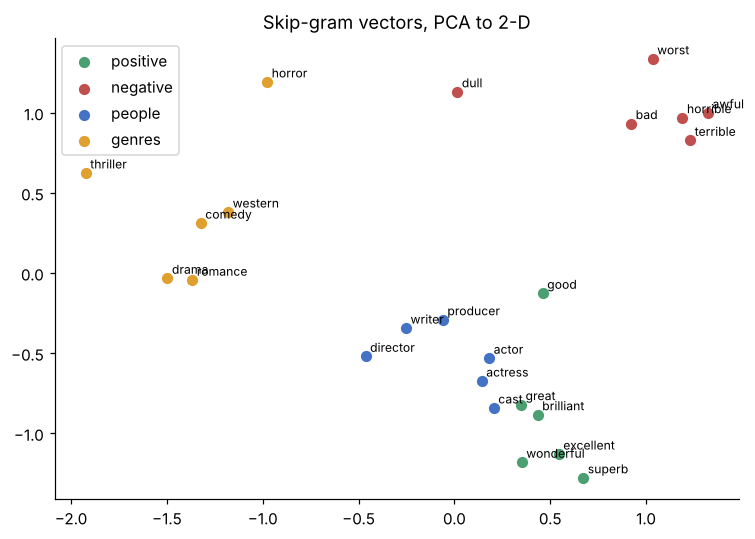

In [15]:
# 2-D picture of the Skip-gram space (PCA of selected words)
from sklearn.decomposition import PCA
groups_w = {"positive": ["good", "great", "excellent", "wonderful", "superb", "brilliant"],
            "negative": ["bad", "terrible", "awful", "horrible", "worst", "dull"],
            "people":   ["actor", "actress", "director", "writer", "producer", "cast"],
            "genres":   ["comedy", "horror", "thriller", "drama", "romance", "western"]}
colors = {"positive": "#4c9f70", "negative": "#c0504d", "people": "#4472c4", "genres": "#e0a030"}
words = [w for g in groups_w.values() for w in g if w in emb["skipgram"].key_to_index]
P = PCA(n_components=2, random_state=0).fit_transform(np.vstack([emb["skipgram"][w] for w in words]))
fig, ax = plt.subplots(figsize=(7, 5))
for g, ws in groups_w.items():
    idx = [words.index(w) for w in ws if w in words]
    ax.scatter(P[idx, 0], P[idx, 1], color=colors[g], label=g, s=40)
for w, (x, y) in zip(words, P): ax.annotate(w, (x, y), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.set_title("Skip-gram vectors, PCA to 2-D"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "phase2_embedding_pca.png"); plt.show()

## C4. Count-based vs learned representations
Below, the facts measured on **our** data. The last rows come from a small sanity check: 10,000 randomly chosen reviews (stratified 80/20 split, fixed seed), each represented with `vectorize_many(...)` and fed to an untuned logistic regression. It is only a quick check that the representations carry sentiment information, **not** a benchmark (the vectorizers were fitted on the full corpus and there is a single split).

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

sample = df.sample(10000, random_state=42)
y = sample.label.values
tr, te = train_test_split(np.arange(len(sample)), test_size=0.2, stratify=y, random_state=42)
docs_s = sample.clean_text.tolist()

acc = {}
for m in V.METHODS:
    t0 = time.time()
    X = V.vectorize_many(docs_s, method=m, clean=False)       # already-clean text -> skip cleaning
    if m in V.COUNT_METHODS:
        clf = LogisticRegression(max_iter=2000, solver="liblinear").fit(X[tr], y[tr]); pred = clf.predict(X[te])
    else:
        sc = StandardScaler().fit(X[tr])
        clf = LogisticRegression(max_iter=2000).fit(sc.transform(X[tr]), y[tr]); pred = clf.predict(sc.transform(X[te]))
    acc[m] = float((pred == y[te]).mean())
    print(f"{m:12s} dims={X.shape[1]:>7,}  accuracy={acc[m]:.3f}  ({time.time() - t0:.0f}s)")
RESULTS["sanity_accuracy"] = {k: round(v, 4) for k, v in acc.items()}

bow          dims= 79,320  accuracy=0.837  (1s)


tfidf        dims= 79,320  accuracy=0.843  (1s)


tfidf_ngram  dims=182,415  accuracy=0.847  (1s)


cbow         dims=    100  accuracy=0.850  (1s)


skipgram     dims=    100  accuracy=0.860  (1s)


fasttext     dims=    100  accuracy=0.860  (2s)


In [17]:
oov_doc = "fantastik excellentt"       # two misspelled words that occur in NO vocabulary (not even the full BoW one)
norms = {m: float(np.linalg.norm(V.vectorize(oov_doc, m, dense=True))) for m in V.METHODS}

def sp_(x): return f"{x:.2f} %"
comp = pd.DataFrame({
    "dimensions": {"bow": f"{summary['bow']['shape'][1]:,}", "tfidf": f"{summary['tfidf']['shape'][1]:,}",
                   "tfidf_ngram": f"{summary['tfidf_ngram']['shape'][1]:,}", "cbow": "100", "skipgram": "100", "fasttext": "100"},
    "sparsity (% zeros)": {"bow": sp_(summary["bow"]["sparsity_pct"]), "tfidf": sp_(summary["tfidf"]["sparsity_pct"]),
                           "tfidf_ngram": sp_(summary["tfidf_ngram"]["sparsity_pct"]), "cbow": "0 % (dense)",
                           "skipgram": "0 % (dense)", "fasttext": "0 % (dense)"},
    "saved file (MB)": {m: summary[m]["file_mb"] for m in V.METHODS},
    "vector of 'fantastik excellentt' (OOV)": {m: ("all zeros" if norms[m] == 0 else f"non-zero (norm {norms[m]:.2f})") for m in V.METHODS},
    "sanity accuracy (10k reviews)": {m: f"{acc[m]:.3f}" for m in V.METHODS},
})
display(comp)
RESULTS["comparison_oov_norms"] = {k: round(v, 3) for k, v in norms.items()}

,dimensions,sparsity (% zeros),saved file (MB),vector of 'fantastik excellentt' (OOV),sanity accuracy (10k reviews)
bow,"79,320",99.88 %,0.7,all zeros,0.837
tfidf,"79,320",99.88 %,0.8,all zeros,0.843
tfidf_ngram,"182,415",99.92 %,2.0,all zeros,0.847
cbow,100,0 % (dense),12.7,all zeros,0.850
skipgram,100,0 % (dense),12.7,all zeros,0.860
fasttext,100,0 % (dense),52.7,non-zero (norm 2.05),0.860


### Count-based vs learned representations on our data

| | Count-based (BoW, TF-IDF, n-grams) | Learned (Word2Vec, fastText) |
|---|---|---|
| **Dimensionality** | 79,320 (unigrams) to 182,415 (uni+bigrams, df >= 5); one column per word or phrase | 100 for every model |
| **Sparsity** | 99.88 % to 99.92 % zeros, so it must be stored as a sparse matrix (37 MB; the dense version would be 15.7 GB) | 0 % zeros (dense); the whole corpus is a 49,582 x 100 matrix of 20 MB |
| **Unseen / misspelled words** | ignored: the vector is all zeros for `fantastik excellentt` | Word2Vec: no vector, document vector is zero; **fastText builds one** from character n-grams (non-zero, norm 2.05) |
| **What it captures** | which words occur and how distinctive they are in a review (TF-IDF); n-grams add short phrases and negation (*not waste time*). Every word is its own independent column: *good* and *great* are unrelated | the meaning of words as used in context: neighbours, similarities, analogies. A document vector is the mean of its word vectors, so word order is lost |
| **Interpretability** | high: every feature is a word or phrase with a weight | low: the 100 dimensions have no individual meaning |
| **Needs training / corpus size** | no training, works on any size | needs enough text: with 6 million tokens, rare words are learned poorly (see *performace*) |
| **Sentiment quirk** | *not* gets the smallest TF-IDF weight although it flips sentiment | *good* and *bad* are close neighbours (antonym problem) |

**Quick sanity check (10,000 reviews, 8,000 train / 2,000 test, untuned logistic regression):** BoW 0.837, TF-IDF 0.843, TF-IDF with bigrams 0.847, CBOW 0.850, Skip-gram 0.860, fastText 0.860. The 100-dimensional embeddings do as well as or slightly better than representations that are 800 to 1,800 times wider, which shows that they carry the sentiment signal compactly. The gaps are only 1 to 2 points on a single 2,000-review test split (standard error about 0.8 points), so we do **not** claim that one representation wins; the real comparison belongs to Phase 3.

**Caution:** our corpus (6.0 million tokens, 29,485 words with at least 5 occurrences) is small for embeddings. Neighbours of frequent words are convincing, but rare words, long lists of neighbours and the analogy tests should be read cautiously.

# Part D: Package for the next phase

## D1. Saved models
`python src/representations.py` fits and saves everything once under `models/`:
vectorizers with `joblib`, embeddings as gensim `KeyedVectors` (`.kv`, only the vectors are kept, which is all Phase 3 needs; use `--force` to retrain).

In [18]:
mdir = Path("../models")
files = pd.DataFrame([{"file": p.name, "size MB": round(p.stat().st_size / 1e6, 1)} for p in sorted(mdir.iterdir())])
display(files)
print("Total: %.1f MB" % files["size MB"].sum())

,file,size MB
0,bow_vectorizer.joblib,0.7
1,fasttext.kv,52.7
2,tfidf_ngram_vectorizer.joblib,2.0
3,tfidf_vectorizer.joblib,0.8
4,word2vec_cbow.kv,12.7
5,word2vec_skipgram.kv,12.7


Total: 81.6 MB


## D2. The `vectorize()` interface
`src/vectorize.py` is the single entry point for Phase 3: **raw document in, vector out**. It runs the Phase 1 cleaning, then the chosen representation. Models are loaded lazily once per process and never retrained.

```python
from vectorize import vectorize, vectorize_many, available_methods
v = vectorize("raw review text", method="tfidf")        # sparse (1, n_features)
X = vectorize_many(list_of_raw_reviews, method="fasttext")   # dense (n_docs, 100)
```
Count-based methods return a scipy sparse matrix (or a dense array with `dense=True`); embedding methods return the mean of the word vectors (a zero vector if no word can be embedded).

In [19]:
raw = "This movie was fantastik!!! <br /><br />Best film of the year, I'd give it 10/10. Not boring at all."
print("Raw    :", raw)
print("Cleaned:", V.clean_text(raw), "\n")
print("Available methods:", V.available_methods(), "\n")

V._cache.clear()
t0 = time.time()
for m in V.METHODS:
    v = V.vectorize(raw, m)
    if m in V.COUNT_METHODS:
        print(f"{m:12s} -> sparse {v.shape}, {v.nnz} non-zero entries")
    else:
        print(f"{m:12s} -> dense  {v.shape}, norm {np.linalg.norm(v):.3f}")
print(f"\nLoading all six models and vectorizing took {time.time() - t0:.1f}s in total (nothing was retrained).")

batch = V.vectorize_many([raw, "Terrible acting.", "A wonderful, moving film."], method="skipgram")
print("vectorize_many ->", batch.shape)

print("\nOOV behaviour of document vectors for 'fantastik excellentt':")
for m in ("cbow", "skipgram", "fasttext"):
    print(f"  {m:9s} norm = {np.linalg.norm(V.vectorize('fantastik excellentt', m)):.3f}")

Raw    : This movie was fantastik!!! <br /><br />Best film of the year, I'd give it 10/10. Not boring at all.
Cleaned: movie fantastik best film year would give not bore 

Available methods: ('bow', 'tfidf', 'tfidf_ngram', 'cbow', 'skipgram', 'fasttext') 

bow          -> sparse (1, 79320), 8 non-zero entries


tfidf        -> sparse (1, 79320), 8 non-zero entries


tfidf_ngram  -> sparse (1, 182415), 14 non-zero entries
cbow         -> dense  (100,), norm 7.734
skipgram     -> dense  (100,), norm 1.538


fasttext     -> dense  (100,), norm 1.408

Loading all six models and vectorizing took 1.1s in total (nothing was retrained).
vectorize_many -> (3, 100)

OOV behaviour of document vectors for 'fantastik excellentt':
  cbow      norm = 0.000
  skipgram  norm = 0.000
  fasttext  norm = 2.050


## Reproducibility
```
python src/load_data.py        # Phase 1: raw data
python src/cleaning.py         # Phase 1: output/cleaned_data.csv
python src/representations.py  # Phase 2: models/ (about 15 minutes on one CPU core)
python src/vectorize.py "some review text"   # quick test of the interface
```
Then run this notebook from the `notebooks/` folder.

In [20]:
Path("../output/phase2_results.json").write_text(json.dumps(RESULTS, indent=2, default=str))
print("Saved key numbers to output/phase2_results.json")

Saved key numbers to output/phase2_results.json
